In [1]:
%pip install -q numpy scipy matplotlib qiskit==2.3.1 qiskit-aer==0.17.2 qiskit-ibm-runtime==0.50.0


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, os, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))          # makes `evqaoa` and `experiments` importable
OUT = ROOT / 'results' / '05_noise'
OUT.mkdir(parents=True, exist_ok=True)
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeFez
from experiments.noise import *
T0 = time.time()

# 05 - Noisy simulation: how far does QAOA survive on a real chip?

**Motivation.** Notebooks 01-04 ran QAOA on a perfect simulator. Real quantum computers make errors on every gate
and every measurement. This notebook asks the honest question: *if we ran our EV-charging QAOA on IBM hardware, how
much of the answer survives?* We answer it offline, with **FakeFez** (a frozen copy of the calibration data of the 156-qubit
`ibm_fez` chip) so no QPU time is used. We then put our simulation next to the **real `ibm_fez` run** saved by the upstream
project (Yash Khamkar, MIT licence - credited).

**What improved over the starting prototype?** The upstream prototype only ran the XY mixer with a basis start on hardware, and
its output was very noisy. Here we (1) compare three circuit designs fairly under the same noise, (2) add cheap offline
error mitigation (post-selection on feasibility + local readout correction), and (3) show how the feasible rate falls with noise strength.

**Workflow**
1. Optimise the QAOA angles on the *ideal* statevector (COBYLA, fixed seeds). Training on noise would be slow and unneeded for a study.
2. Transpile for FakeFez (`optimization_level=3`, fixed seed) and read off depth and two-qubit-gate count.
3. Sample 4096 shots on the noisy simulator `AerSimulator.from_backend(FakeFez())`.
4. Score every sample with the **penalty-free** objective: feasible rate, P(optimal), approximation ratio of feasible samples, Hellinger fidelity vs ideal.
5. Mitigate and compare.

**Three configurations**
- **(a) XY + basis start**: XY mixer swaps a 1 and a 0 inside one vehicle, so a valid schedule can never become invalid *in the ideal circuit*. Start = X gates (shallow).
- **(b) XY + Dicke start**: same mixer, but starts from the uniform superposition of all valid schedules (deeper state preparation).
- **(c) X mixer + penalty**: standard transverse-field mixer; validity is only encouraged through a penalty term in the cost function.

In [3]:
SHOTS, PENALTY, PS = 4096, 1.5, (1, 2, 3)
backend = FakeFez()
sim = AerSimulator.from_backend(backend)
problem = setup_problem()                      # penalty-free scoring problem
inst = problem[0]
E_best, E_worst = problem[4], problem[5]
RANDOM_RATE = 216 / 2 ** inst.n
uniform = {format(i, f'0{inst.n}b'): 1 / 2 ** inst.n for i in range(2 ** inst.n)}
uniform_scores = score(uniform, problem)
print(f"Random-guess feasible rate: {RANDOM_RATE:.3%} | optimum energy {E_best:.4f} | worst valid {E_worst:.4f}")
print('Uniform-random reference:', {k: round(v, 4) for k, v in uniform_scores.items()})
CONFIGS = {'XY + basis': ('xy', 'basis', 0.0),
           'XY + Dicke': ('xy', 'dicke', 0.0),
           f'X + penalty ({PENALTY})': ('x', None, PENALTY)}

Random-guess feasible rate: 5.273% | optimum energy 0.5175 | worst valid 0.9333
Uniform-random reference: {'feasible_rate': 0.0527, 'p_optimal': 0.0015, 'mean_feasible_energy': 0.6548, 'approx_ratio': 0.6698}


## Experiment 1: three designs x three depths on FakeFez noise
Each run trains angles on the ideal simulator, then samples on the noisy one. We also calibrate readout error by running all-0 and all-1 circuits on the *same physical qubits*
and apply a local (per-qubit) correction. This takes a few minutes.

In [4]:
results, dists = [], {}
for name, (mixer, start, pen) in CONFIGS.items():
    pr = setup_problem(penalty=pen)            # Hamiltonian with penalty (c) or without (a, b)
    for p in PS:
        t = time.time()
        circ, theta = optimise_angles(inst, pr[1], p, mixer, start, seed=0)
        ideal = ideal_distribution(circ, theta)
        tc = transpile_for(circ, theta, backend)
        counts = run_counts(tc, sim, SHOTS)
        rates = calibrate_readout(backend, sim, measured_physical_qubits(tc))
        ro = local_readout_mitigate(counts, rates)
        post = postselect(counts, inst)
        row = dict(config=name, p=p, **circuit_stats(tc),
                   hellinger=hellinger(counts, ideal), ideal=score(ideal, problem), raw=score(counts, problem),
                   readout=score(ro, problem), post_feasible_kept=sum(post.values()) / SHOTS,
                   post=score(post, problem) if post else None,
                   readout_then_post=score(postselect(ro, inst), problem) if postselect(ro, inst) else None,
                   hellinger_readout=hellinger(ro, ideal),
                   mean_readout_error=float(np.mean([a + b for a, b in rates]) / 2))
        results.append(row); dists[(name, p)] = counts
        print(f"{name:<18} p={p} depth={row['depth']:>4} 2q={row['two_qubit_gates']:>4} "
              f"feasible={row['raw']['feasible_rate']:.3f} (ideal {row['ideal']['feasible_rate']:.3f}) "
              f"Hell={row['hellinger']:.3f} [{time.time()-t:.0f}s]")
json.dump(results, open(OUT / 'noisy_results.json', 'w'), indent=1, default=float)

XY + basis         p=1 depth= 156 2q= 118 feasible=0.618 (ideal 1.000) Hell=0.610 [18s]


XY + basis         p=2 depth= 318 2q= 247 feasible=0.431 (ideal 1.000) Hell=0.414 [30s]


XY + basis         p=3 depth= 570 2q= 398 feasible=0.318 (ideal 1.000) Hell=0.290 [46s]


XY + Dicke         p=1 depth= 282 2q= 209 feasible=0.515 (ideal 1.000) Hell=0.504 [33s]


XY + Dicke         p=2 depth= 391 2q= 357 feasible=0.361 (ideal 1.000) Hell=0.315 [51s]


XY + Dicke         p=3 depth= 666 2q= 523 feasible=0.234 (ideal 1.000) Hell=0.193 [67s]


X + penalty (1.5)  p=1 depth= 230 2q= 112 feasible=0.308 (ideal 0.402) Hell=0.733 [17s]


X + penalty (1.5)  p=2 depth= 480 2q= 305 feasible=0.399 (ideal 0.964) Hell=0.487 [37s]


X + penalty (1.5)  p=3 depth= 754 2q= 480 feasible=0.302 (ideal 0.988) Hell=0.354 [56s]


In [5]:
hdr = f"{'config':<18}{'p':>2}{'depth':>7}{'2q':>5}{'feas':>7}{'P(opt)':>8}{'approx':>8}{'Hellinger':>10}"
print(hdr); print('-' * len(hdr))
for r in results:
    print(f"{r['config']:<18}{r['p']:>2}{r['depth']:>7}{r['two_qubit_gates']:>5}{r['raw']['feasible_rate']:>7.3f}"
          f"{r['raw']['p_optimal']:>8.4f}{r['raw']['approx_ratio']:>8.3f}{r['hellinger']:>10.3f}")
print(f"{'uniform random':<18}{'-':>2}{'-':>7}{'-':>5}{uniform_scores['feasible_rate']:>7.3f}"
      f"{uniform_scores['p_optimal']:>8.4f}{uniform_scores['approx_ratio']:>8.3f}{'-':>10}")

config             p  depth   2q   feas  P(opt)  approx Hellinger
-----------------------------------------------------------------
XY + basis         1    156  118  0.618  0.0000   0.519     0.610
XY + basis         2    318  247  0.431  0.0183   0.735     0.414
XY + basis         3    570  398  0.318  0.0229   0.756     0.290
XY + Dicke         1    282  209  0.515  0.0164   0.694     0.504
XY + Dicke         2    391  357  0.361  0.0415   0.821     0.315
XY + Dicke         3    666  523  0.234  0.0266   0.824     0.193
X + penalty (1.5)  1    230  112  0.308  0.0076   0.668     0.733
X + penalty (1.5)  2    480  305  0.399  0.0095   0.678     0.487
X + penalty (1.5)  3    754  480  0.302  0.0068   0.659     0.354
uniform random     -      -    -  0.053  0.0015   0.670         -


## Plot 1: feasible rate per design and depth
The dashed line is what a random 12-bit guess achieves (216 of 4096 bitstrings are valid schedules). The hatched outlines show the *ideal* (noise-free) feasible rate.

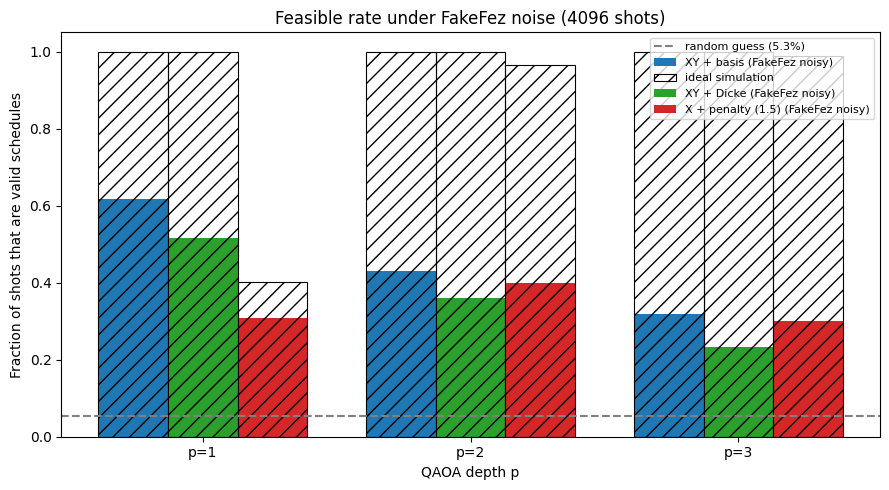

In [6]:
names = list(CONFIGS); xs = np.arange(len(PS)); w = 0.26
colors = ['#1f77b4', '#2ca02c', '#d62728']
fig, ax = plt.subplots(figsize=(9, 5))
for i, nme in enumerate(names):
    rr = [r for r in results if r['config'] == nme]
    ax.bar(xs + (i - 1) * w, [r['raw']['feasible_rate'] for r in rr], w, color=colors[i], label=f'{nme} (FakeFez noisy)')
    ax.bar(xs + (i - 1) * w, [r['ideal']['feasible_rate'] for r in rr], w, fill=False, edgecolor='black', hatch='//', lw=0.8,
           label='ideal simulation' if i == 0 else None)
ax.axhline(RANDOM_RATE, color='gray', ls='--', label=f'random guess ({RANDOM_RATE:.1%})')
ax.set_xticks(xs); ax.set_xticklabels([f'p={p}' for p in PS])
ax.set_xlabel('QAOA depth p'); ax.set_ylabel('Fraction of shots that are valid schedules')
ax.set_title('Feasible rate under FakeFez noise (4096 shots)'); ax.legend(loc='upper right', fontsize=8)
fig.tight_layout(); fig.savefig(OUT / 'feasible_rate_by_config.png', dpi=150); plt.show()

## Plot 2: quality of the valid answers (approximation ratio)
Approximation ratio 1 = always the optimal schedule, 0 = always the worst valid schedule. Only valid samples are scored, so read it together with Plot 1.

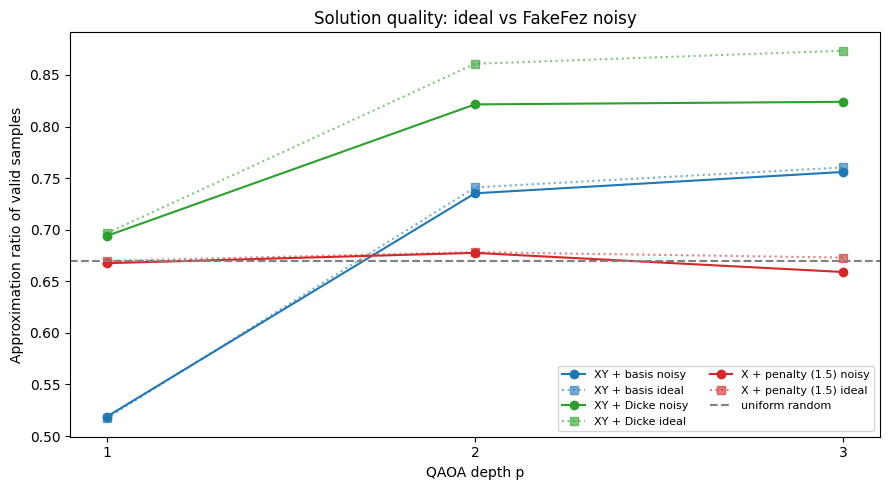

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
for i, nme in enumerate(names):
    rr = [r for r in results if r['config'] == nme]
    ax.plot(PS, [r['raw']['approx_ratio'] for r in rr], 'o-', color=colors[i], label=f'{nme} noisy')
    ax.plot(PS, [r['ideal']['approx_ratio'] for r in rr], 's:', color=colors[i], alpha=0.6, label=f'{nme} ideal')
ax.axhline(uniform_scores['approx_ratio'], color='gray', ls='--', label='uniform random')
ax.set_xticks(PS); ax.set_xlabel('QAOA depth p'); ax.set_ylabel('Approximation ratio of valid samples')
ax.set_title('Solution quality: ideal vs FakeFez noisy'); ax.legend(fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig(OUT / 'approx_ratio.png', dpi=150); plt.show()

## Plot 3: more two-qubit gates, fewer valid answers
Two-qubit gates are the dominant error source on superconducting chips (about 0.3% error each on FakeFez). Each point is one (design, p) run.

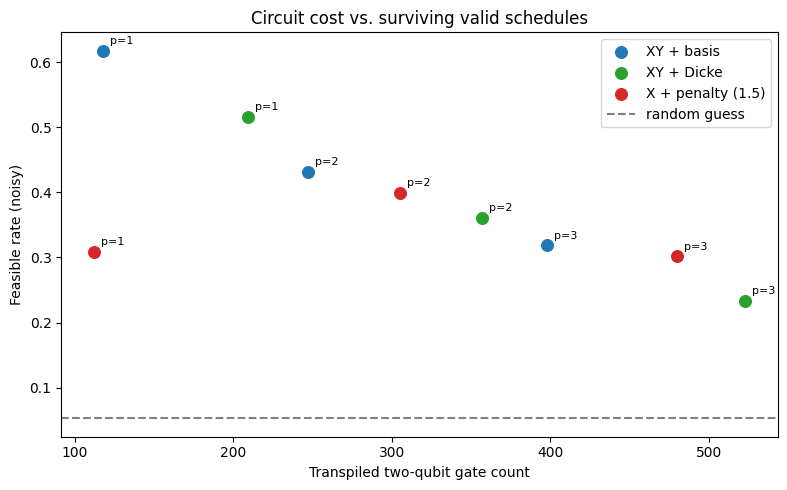

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, nme in enumerate(names):
    rr = [r for r in results if r['config'] == nme]
    ax.scatter([r['two_qubit_gates'] for r in rr], [r['raw']['feasible_rate'] for r in rr], s=70, color=colors[i], label=nme)
    for r in rr:
        ax.annotate(f"p={r['p']}", (r['two_qubit_gates'], r['raw']['feasible_rate']), textcoords='offset points', xytext=(5, 5), fontsize=8)
ax.axhline(RANDOM_RATE, color='gray', ls='--', label='random guess')
ax.set_xlabel('Transpiled two-qubit gate count'); ax.set_ylabel('Feasible rate (noisy)')
ax.set_title('Circuit cost vs. surviving valid schedules'); ax.legend()
fig.tight_layout(); fig.savefig(OUT / 'gates_vs_feasible.png', dpi=150); plt.show()

## Error mitigation (cheap, offline)
- **Post-selection on feasibility**: throw away shots that are not valid schedules. The XY mixer makes this a natural *error detector*: an ideal XY circuit never produces an invalid bitstring, so every invalid shot is proof that an error occurred. The price is fewer usable shots.
- **Local readout correction**: measure how often each qubit flips on |0> and |1> (calibration circuits) and invert the independent per-qubit flip matrices.

Post-selection makes the feasible rate 100% by construction. Because our approximation ratio is already computed over valid samples only, it cannot change either; the real gain is **P(optimal | kept)**, the chance that a kept shot is the best schedule, which we compare with the raw P(optimal), together with the fraction of shots kept.

In [9]:
hdr = f"{'config':<18}{'p':>2}{'kept':>7}{'Popt raw':>9}{'Popt post':>10}{'Popt r+p':>9}{'feas raw':>9}{'feas read':>10}{'ro err':>8}"
print(hdr); print('-' * len(hdr))
g = lambda d, k: d[k] if d else float('nan')
for r in results:
    print(f"{r['config']:<18}{r['p']:>2}{r['post_feasible_kept']:>7.3f}{r['raw']['p_optimal']:>9.4f}"
          f"{g(r['post'], 'p_optimal'):>10.4f}{g(r['readout_then_post'], 'p_optimal'):>9.4f}"
          f"{r['raw']['feasible_rate']:>9.3f}{r['readout']['feasible_rate']:>10.3f}{r['mean_readout_error']:>8.4f}")

config             p   kept Popt raw Popt post Popt r+p feas raw feas read  ro err
----------------------------------------------------------------------------------
XY + basis         1  0.618   0.0000    0.0000   0.0000    0.618     0.664  0.0073
XY + basis         2  0.431   0.0183    0.0425   0.0427    0.431     0.452  0.0078
XY + basis         3  0.318   0.0229    0.0721   0.0725    0.318     0.332  0.0077
XY + Dicke         1  0.515   0.0164    0.0318   0.0318    0.515     0.540  0.0082
XY + Dicke         2  0.361   0.0415    0.1151   0.1157    0.361     0.377  0.0084
XY + Dicke         3  0.234   0.0266    0.1139   0.1156    0.234     0.241  0.0076
X + penalty (1.5)  1  0.308   0.0076    0.0246   0.0243    0.308     0.318  0.0079
X + penalty (1.5)  2  0.399   0.0095    0.0238   0.0237    0.399     0.415  0.0078
X + penalty (1.5)  3  0.302   0.0068    0.0227   0.0224    0.302     0.312  0.0086


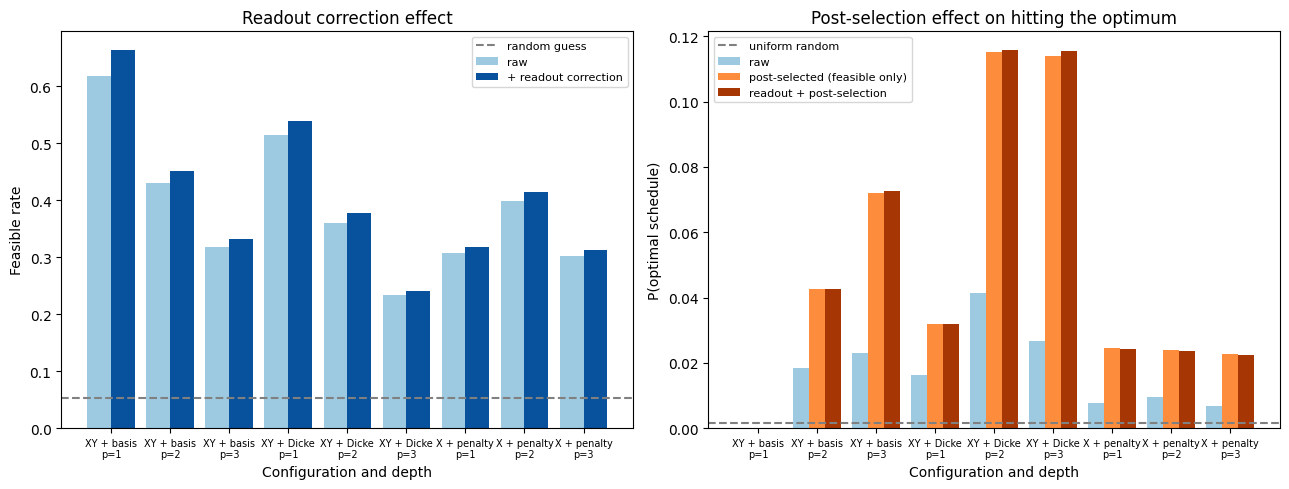

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
labels = [f"{r['config'].split(' (')[0]}\np={r['p']}" for r in results]; xs = np.arange(len(results))
axes[0].bar(xs - 0.2, [r['raw']['feasible_rate'] for r in results], 0.4, label='raw', color='#9ecae1')
axes[0].bar(xs + 0.2, [r['readout']['feasible_rate'] for r in results], 0.4, label='+ readout correction', color='#08519c')
axes[0].axhline(RANDOM_RATE, color='gray', ls='--', label='random guess')
axes[0].set_ylabel('Feasible rate'); axes[0].set_title('Readout correction effect')
axes[1].bar(xs - 0.27, [r['raw']['p_optimal'] for r in results], 0.27, label='raw', color='#9ecae1')
axes[1].bar(xs, [g(r['post'], 'p_optimal') for r in results], 0.27, label='post-selected (feasible only)', color='#fd8d3c')
axes[1].bar(xs + 0.27, [g(r['readout_then_post'], 'p_optimal') for r in results], 0.27, label='readout + post-selection', color='#a63603')
axes[1].axhline(uniform_scores['p_optimal'], color='gray', ls='--', label='uniform random')
axes[1].set_ylabel('P(optimal schedule)'); axes[1].set_title('Post-selection effect on hitting the optimum')
for a in axes:
    a.set_xticks(xs); a.set_xticklabels(labels, fontsize=7); a.set_xlabel('Configuration and depth'); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / 'mitigation.png', dpi=150); plt.show()

## Noise-strength sweep (generic depolarizing noise)
To see *how fast* quality dies, we use a simple noise model instead of FakeFez: every CZ gets two-qubit depolarizing error `p2q` (one-qubit gates get `p2q/10`), no readout error, all-to-all connectivity with native gates `cz, rz, sx, x`.
Real `ibm_fez` is roughly at p2q ~ 3e-3. We sweep p2q for XY+basis and X+penalty at p=1 and p=2.

In [11]:
SWEEP_P2Q = [0, 0.001, 0.003, 0.006, 0.012, 0.025]
SWEEP_SHOTS = 2048
sweep = []
for name in ('XY + basis', f'X + penalty ({PENALTY})'):
    mixer, start, pen = CONFIGS[name]
    pr = setup_problem(penalty=pen)
    for p in (1, 2):
        circ, theta = optimise_angles(inst, pr[1], p, mixer, start, seed=0)
        tc = generic_transpile(circ, theta)
        n2q = circuit_stats(tc)['two_qubit_gates']
        for e in SWEEP_P2Q:
            gsim = AerSimulator(noise_model=depolarizing_model(e), basis_gates=['cz', 'rz', 'sx', 'x'])
            c = run_counts(tc, gsim, SWEEP_SHOTS)
            sweep.append(dict(config=name, p=p, p2q=e, two_qubit_gates=n2q, feasible=feasible_fraction(c, inst)))
        print(name, p, 'done', n2q, 'cz gates')
json.dump(sweep, open(OUT / 'noise_sweep.json', 'w'), indent=1)

XY + basis 1 done 59 cz gates


XY + basis 2 done 118 cz gates


X + penalty (1.5) 1 done 60 cz gates


X + penalty (1.5) 2 done 120 cz gates


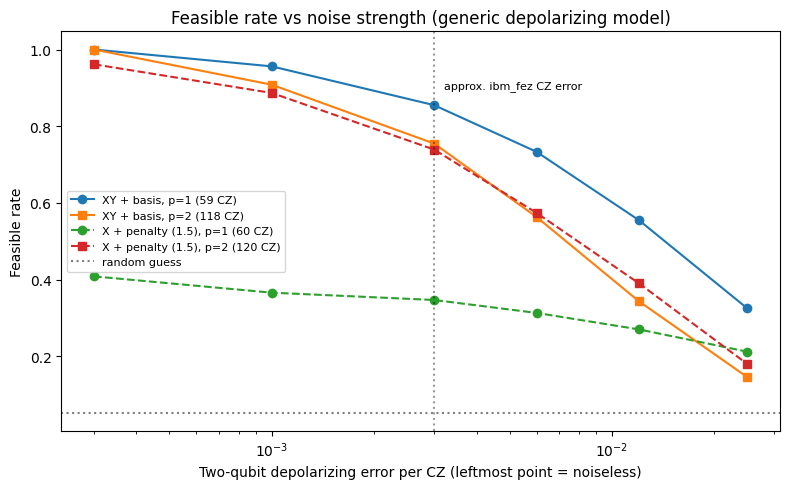

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
x_axis = [e if e > 0 else 3e-4 for e in SWEEP_P2Q]
for (name, p), mk in zip([(n, p) for n in ('XY + basis', f'X + penalty ({PENALTY})') for p in (1, 2)], ['o-', 's-', 'o--', 's--']):
    rr = [r for r in sweep if r['config'] == name and r['p'] == p]
    ax.plot(x_axis, [r['feasible'] for r in rr], mk, label=f"{name}, p={p} ({rr[0]['two_qubit_gates']} CZ)")
ax.axhline(RANDOM_RATE, color='gray', ls=':', label='random guess')
ax.axvline(3e-3, color='k', ls=':', alpha=0.4); ax.text(3.2e-3, 0.9, 'approx. ibm_fez CZ error', fontsize=8)
ax.set_xscale('log'); ax.set_xlabel('Two-qubit depolarizing error per CZ (leftmost point = noiseless)')
ax.set_ylabel('Feasible rate'); ax.set_title('Feasible rate vs noise strength (generic depolarizing model)')
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(OUT / 'feasible_vs_noise.png', dpi=150); plt.show()

## Real `ibm_fez` data from the upstream project (credited)
The upstream notebook (Yash Khamkar, MIT) ran XY + basis start on `ibm_fez` with dynamical decoupling and gate/measurement twirling and saved 4096 counts. We only *load* those counts - nothing is submitted to IBM.
The file name says `run2`; the JSON does not record the circuit depth p, so we compare it against the ideal distributions of both p=1 and p=2 (XY + basis, our re-optimised angles - the upstream angles are not stored with the counts). Note the angles may differ from the hardware run, so Hellinger values are indicative only.

In [13]:
hw = load_counts(ROOT / 'upstream/results/hw_counts_run2_mitigated.json')
info = json.load(open(ROOT / 'upstream/results/hw_job_info_run2.json'))
print('Loaded', sum(hw.values()), 'shots,', len(hw), 'distinct bitstrings;', info)
pr_free = setup_problem()
ideal_ref, sim_ref = {}, {}
for p in (1, 2):
    circ, theta = optimise_angles(inst, pr_free[1], p, 'xy', 'basis', seed=0)
    ideal_ref[p] = ideal_distribution(circ, theta)
    sim_ref[p] = dists[('XY + basis', p)]
hw_score = score(hw, problem)
hw_post = postselect(hw, inst)
hw_row = dict(label='real ibm_fez (upstream)', **hw_score, hellinger_vs_ideal_p1=hellinger(hw, ideal_ref[1]),
              hellinger_vs_ideal_p2=hellinger(hw, ideal_ref[2]), post_kept=sum(hw_post.values()) / SHOTS,
              post_approx_ratio=score(hw_post, problem)['approx_ratio'] if hw_post else None)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in hw_row.items()})
side = {'ideal sim p=2': score(ideal_ref[2], problem), 'FakeFez noisy sim p=2': score(sim_ref[2], problem),
        'real ibm_fez (upstream)': hw_score, 'uniform random': uniform_scores}
side['ideal sim p=1'] = score(ideal_ref[1], problem); side['FakeFez noisy sim p=1'] = score(sim_ref[1], problem)
ones = lambda d: sum(k.count('1') * v for k, v in normalise(d).items())
print(f"Mean number of 1s per shot (valid schedules have 6): ideal p=2 {ones(ideal_ref[2]):.2f} | FakeFez p=2 {ones(sim_ref[2]):.2f} | real ibm_fez {ones(hw):.2f}")
hw_row['mean_ones'] = ones(hw)
json.dump(dict(side_by_side=side, hardware=hw_row), open(OUT / 'hardware_comparison.json', 'w'), indent=1, default=float)

Loaded 4096 shots, 1516 distinct bitstrings; {'backend': 'ibm_fez', 'job_id': 'db17t3megvvc73bh96m0', 'shots': 4096, 'mitigation': 'DD XpXm + gate twirling + measure twirling'}


{'label': 'real ibm_fez (upstream)', 'feasible_rate': 0.0181, 'p_optimal': 0.0005, 'mean_feasible_energy': 0.6353, 'approx_ratio': 0.7167, 'hellinger_vs_ideal_p1': 0.0001, 'hellinger_vs_ideal_p2': 0.0043, 'post_kept': 0.0181, 'post_approx_ratio': 0.7167}
Mean number of 1s per shot (valid schedules have 6): ideal p=2 6.00 | FakeFez p=2 5.89 | real ibm_fez 3.58


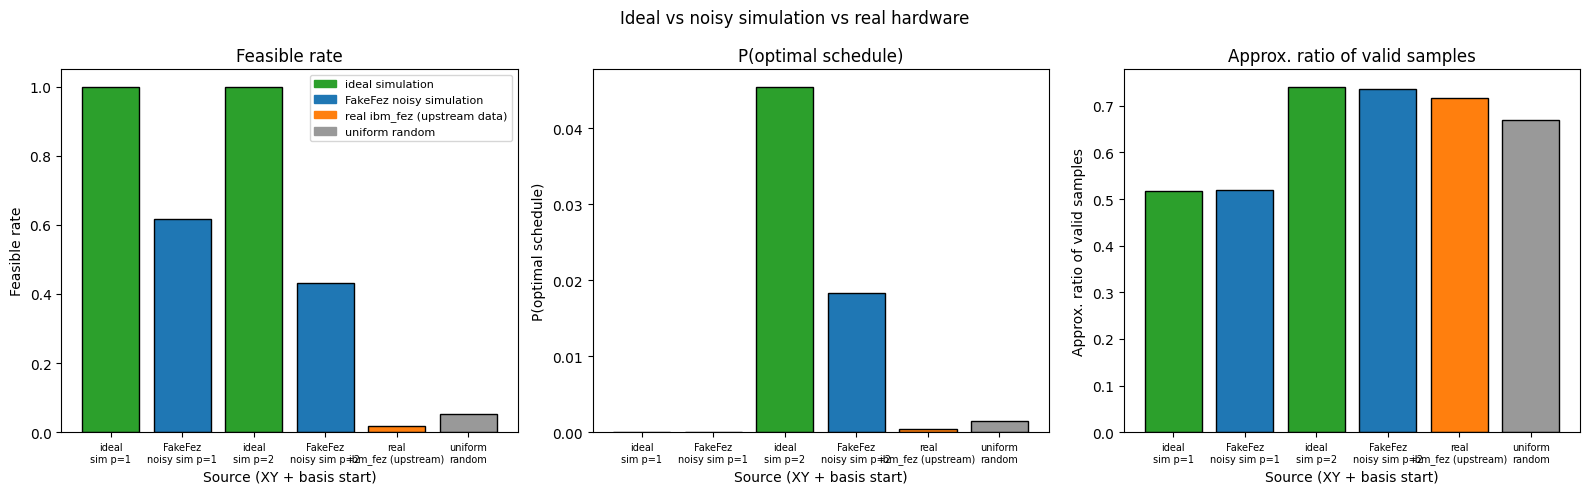

Total notebook runtime: 6.8 min


In [14]:
order = ['ideal sim p=1', 'FakeFez noisy sim p=1', 'ideal sim p=2', 'FakeFez noisy sim p=2', 'real ibm_fez (upstream)', 'uniform random']
cols = ['#2ca02c', '#1f77b4', '#2ca02c', '#1f77b4', '#ff7f0e', '#999999']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, key, ttl in zip(axes, ['feasible_rate', 'p_optimal', 'approx_ratio'],
                        ['Feasible rate', 'P(optimal schedule)', 'Approx. ratio of valid samples']):
    ax.bar(range(len(order)), [side[o][key] for o in order], color=cols, edgecolor='black')
    ax.set_xticks(range(len(order))); ax.set_xticklabels([o.replace(' ', '\n', 1) for o in order], fontsize=7)
    ax.set_ylabel(ttl); ax.set_title(ttl); ax.set_xlabel('Source (XY + basis start)')
from matplotlib.patches import Patch
axes[0].legend(handles=[Patch(color='#2ca02c', label='ideal simulation'), Patch(color='#1f77b4', label='FakeFez noisy simulation'),
                        Patch(color='#ff7f0e', label='real ibm_fez (upstream data)'), Patch(color='#999999', label='uniform random')], fontsize=8)
fig.suptitle('Ideal vs noisy simulation vs real hardware'); fig.tight_layout()
fig.savefig(OUT / 'sim_vs_hardware.png', dpi=150); plt.show()
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min")

## Findings & limitations

**Findings (all numbers from the runs above, 4096 shots, FakeFez, seed-fixed; random guess = 5.3% feasible).**
- **Noise costs more with depth.** XY + basis: feasible rate 61.8% (p=1, 118 two-qubit gates) -> 43.1% (p=2, 247) -> 31.8% (p=3, 398), even though the ideal circuit is 100% feasible. Hellinger fidelity vs ideal falls 0.61 -> 0.41 -> 0.29. Still 6-12x better than random guessing.
- **Dicke start is expensive on hardware.** XY + Dicke needs 209 / 357 / 523 two-qubit gates (p=1/2/3) versus 118 / 247 / 398 for the basis start, so its feasible rate is lower (51.5 / 36.1 / 23.4%). But its answers are better: at p=2, P(optimal) is 4.2% raw (ideal 16.8%) vs 1.8% for XY + basis, and approximation ratio 0.821 vs 0.735 (uniform random: 0.670, P(opt) 0.15%).
- **The XY mixer beats the penalty mixer under noise.** X + penalty (1.5) reaches at best 39.9% feasible (p=2) and its approximation ratio stays near random (0.66-0.68), because its *ideal* p=1 circuit is only 40% feasible and the extra RX/penalty structure still costs 112-480 two-qubit gates.
- **Post-selection works as error detection.** Keeping only valid shots retains 23-62% of shots and lifts P(optimal): XY + Dicke p=2 from 4.2% to 11.5%, XY + basis p=3 from 2.3% to 7.2%. Approximation ratio is unchanged by construction (it already scores valid samples only).
- **Local readout correction is a small effect here**: mean calibrated readout error is only ~0.8% per qubit, so the feasible rate rises by 0.7-4.6 points (e.g. 61.8% -> 66.4% for XY + basis p=1). Gate errors dominate.
- **Noise sweep (generic depolarizing, XY + basis):** feasible rate 100% -> 85.5% at 0.3% CZ error (p=1, 59 CZ) and 75.5% (p=2, 118 CZ); it halves near 1.2% error at p=1 and falls to 14.6% at 2.5% error for p=2.
- **Real hardware (upstream `ibm_fez` run, 4096 shots, DD + twirling):** only 1.8% of shots are valid schedules - *below* the 5.3% random-guess rate - and Hellinger fidelity vs our ideal distributions is ~0.0001 (p=1) / 0.004 (p=2). The mean number of ones per shot is 3.58 versus 6 for any valid schedule (FakeFez: 5.89), i.e. the real output is strongly biased toward |0>, as expected from energy relaxation on a deep circuit. The hardware approximation ratio (0.717) is computed from only 74 valid shots and is not statistically meaningful.

**Limitations (be honest with judges).**
- FakeFez is a *snapshot noise model* (gate/readout errors, T1/T2); it clearly under-predicts the real run (61.8% / 43.1% simulated feasible vs 1.8% measured). The real run probably used a different transpilation, depth and angles; the saved JSON does not record p or the angles, so the hardware comparison is qualitative.
- Angles were optimised on the ideal statevector and never re-tuned under noise; single seed, single 4096-shot sample per cell (feasible-rate standard error about 0.8 points, P(optimal) is a few counts out of 4096 so differences between 1-3% values are not significant).
- The noise sweep uses an all-to-all generic model without readout error or crosstalk, so it is optimistic.
- Readout correction assumes independent per-qubit errors and is calibrated with the same simulator noise model.
- No QPU time was used by this notebook.

**Take-away.** On this 12-qubit problem, noise caps useful depth at about p=2. The best hardware-ready choice is **XY mixer, p=2**: with a basis start for the fewest gates (247 two-qubit gates, 43% feasible), or with a Dicke start when solution quality matters more than depth (11.5% P(optimal) after post-selection). Always post-select on feasibility.
